In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)

# ============================================================
# Load datasets
# ============================================================

train = pd.read_csv("../outputs/train.csv", low_memory=False)
validation = pd.read_csv("../outputs/validation.csv", low_memory=False)
oot_test = pd.read_csv("../outputs/oot_test.csv", low_memory=False)

# Parse issue date
for df in [train, validation, oot_test]:
    df["issue_d"] = pd.to_datetime(df["issue_d"])

print("Train:", train.shape)
print("Validation:", validation.shape)
print("OOT:", oot_test.shape)

Train: (99443, 110)
Validation: (14909, 110)
OOT: (5019, 110)


In [2]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99443 entries, 0 to 99442
Columns: 110 entries, loan_amnt to default_flag
dtypes: datetime64[ns](1), float64(91), int64(1), object(17)
memory usage: 83.5+ MB


In [3]:
train.head()

,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,pymnt_plan,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,disbursement_method,default_flag
0,18000.0,18000.0,18000.0,36 months,11.49,593.49,B,B5,DE/SAR Underwriter,3 years,MORTGAGE,120000.0,Verified,2016-11-01,n,credit_card,Credit card refinancing,990xx,WA,11.85,0.0,Feb-2004,685.0,689.0,1.0,NaN,NaN,8.0,0.0,15013.0,66.1,21.0,w,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,371291.0,3.0,3.0,3.0,4.0,2.0,85524.0,92.0,3.0,7.0,11976.0,84.0,22700.0,0.0,3.0,1.0,14.0,46411.0,6808.0,67.1,0.0,0.0,153.0,62.0,2.0,2.0,4.0,8.0,NaN,2.0,NaN,0.0,2.0,4.0,2.0,5.0,7.0,4.0,10.0,4.0,8.0,0.0,0.0,0.0,7.0,100.0,50.0,0.0,0.0,387487.0,100537.0,20700.0,90237.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,0
1,8725.0,8725.0,8725.0,36 months,23.70,340.94,F,F1,Director of Operations,10+ years,MORTGAGE,29000.0,Verified,2013-12-01,n,other,Paying bills,052xx,VT,23.76,0.0,Nov-2000,660.0,664.0,0.0,64.0,NaN,4.0,0.0,18506.0,101.7,6.0,w,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,70363.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18200.0,NaN,NaN,NaN,0.0,17591.0,0.0,101.7,0.0,0.0,NaN,155.0,102.0,102.0,2.0,102.0,NaN,18.0,NaN,0.0,3.0,3.0,3.0,4.0,0.0,3.0,4.0,3.0,4.0,0.0,0.0,0.0,0.0,83.3,100.0,0.0,0.0,83675.0,18506.0,18200.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,0
2,3000.0,3000.0,3000.0,36 months,15.10,104.15,C,C2,Childrens' Kastle,1 year,RENT,22000.0,Verified,2013-09-01,n,debt_consolidation,Help,140xx,NY,34.58,0.0,Oct-2004,700.0,704.0,0.0,NaN,NaN,16.0,0.0,6880.0,76.4,49.0,f,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,78795.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9000.0,NaN,NaN,NaN,5.0,5253.0,391.0,89.7,0.0,0.0,109.0,103.0,23.0,22.0,0.0,31.0,NaN,23.0,NaN,0.0,5.0,8.0,6.0,7.0,35.0,9.0,14.0,8.0,16.0,0.0,0.0,0.0,0.0,100.0,80.0,0.0,0.0,86903.0,78795.0,3800.0,77903.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,0
3,10300.0,10300.0,10275.0,36 months,14.65,355.30,C,C5,Lab Technician,10+ years,OWN,42619.0,Source Verified,2015-07-01,n,debt_consolidation,Debt consolidation,497xx,MI,31.06,1.0,Oct-1993,720.0,724.0,1.0,23.0,NaN,13.0,0.0,16001.0,40.4,21.0,f,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,37214.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39600.0,NaN,NaN,NaN,3.0,3101.0,19099.0,45.6,0.0,0.0,102.0,178.0,1.0,1.0,0.0,1.0,NaN,1.0,23.0,0.0,4.0,4.0,6.0,8.0,4.0,10.0,16.0,4.0,13.0,0.0,0.0,0.0,2.0,95.2,33.3,0.0,0.0,70852.0,37214.0,35100.0

In [4]:
train.describe().T

,count,mean,min,25%,50%,75%,max,std
loan_amnt,99443.0,14432.685307,500.0,8000.0,12000.0,20000.0,40000.0,8531.457194
funded_amnt,99443.0,14423.424223,500.0,8000.0,12000.0,20000.0,40000.0,8527.422436
funded_amnt_inv,99443.0,14391.348008,0.0,8000.0,12000.0,20000.0,40000.0,8535.852348
int_rate,99443.0,13.141736,5.32,9.71,12.79,15.8,30.99,4.57293
installment,99443.0,438.197713,15.67,252.145,377.11,580.01,1569.11,255.653773
annual_inc,99442.0,75611.588635,0.0,45337.75,65000.0,90000.0,9000000.0,71202.13507
issue_d,99443,2014-12-21 10:55:24.541697024,2007-06-01 00:00:00,2014-04-01 00:00:00,2015-04-01 00:00:00,2016-01-01 00:00:00,2016-12-01 00:00:00,NaN
dti,99438.0,18.172194,0.0,11.88,17.61,24.0,822.0,8.895409
delinq_2yrs,99441.0,0.319496,0.0,0.0,0.0,0.0,21.0,0.87186
fico_range_low,99443.0,695.036252,625.0,670.0,690.0,710.0,845.0,30.972054


In [5]:
target_summary = pd.DataFrame({
    "count": train["default_flag"].value_counts(),
    "percentage": train["default_flag"].value_counts(normalize=True) * 100
})

target_summary

,count,percentage
default_flag,,
0,79871,80.318373
1,19572,19.681627


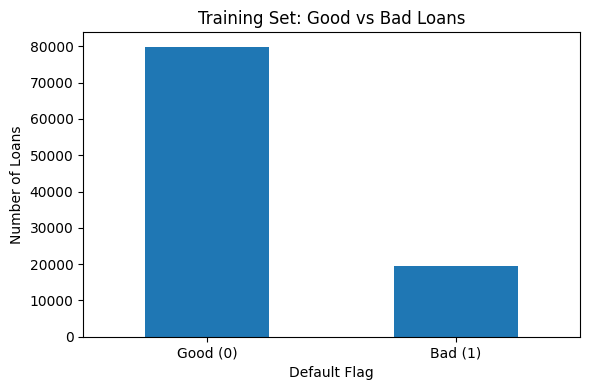

In [6]:
plt.figure(figsize=(6, 4))

train["default_flag"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Default Flag")
plt.ylabel("Number of Loans")
plt.title("Training Set: Good vs Bad Loans")
plt.xticks([0, 1], ["Good (0)", "Bad (1)"], rotation=0)

plt.tight_layout()
plt.show()

In [7]:
yearly_default = (
    train.groupby(train["issue_d"].dt.year)["default_flag"]
    .agg(["count", "sum", "mean"])
)

yearly_default.columns = [
    "loans",
    "defaults",
    "default_rate"
]

yearly_default["default_rate"] *= 100

yearly_default

,loans,defaults,default_rate
issue_d,,,
2007,49,15,30.612245
2008,228,52,22.807018
2009,434,53,12.211982
2010,1089,130,11.937557
2011,1916,294,15.344468
2012,4643,746,16.067198
2013,12185,1938,15.904801
2014,19600,3615,18.443878
2015,33256,6680,20.086601


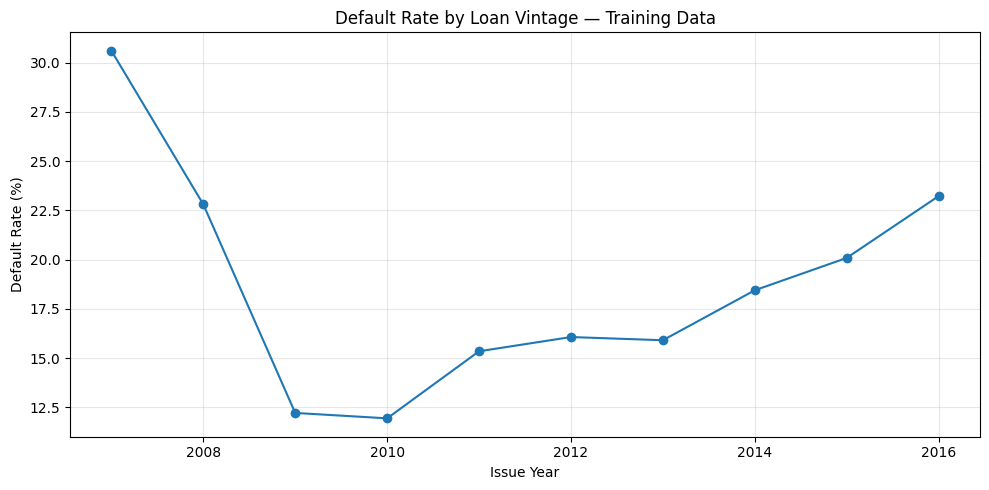

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_default.index,
    yearly_default["default_rate"],
    marker="o"
)

plt.xlabel("Issue Year")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Vintage — Training Data")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

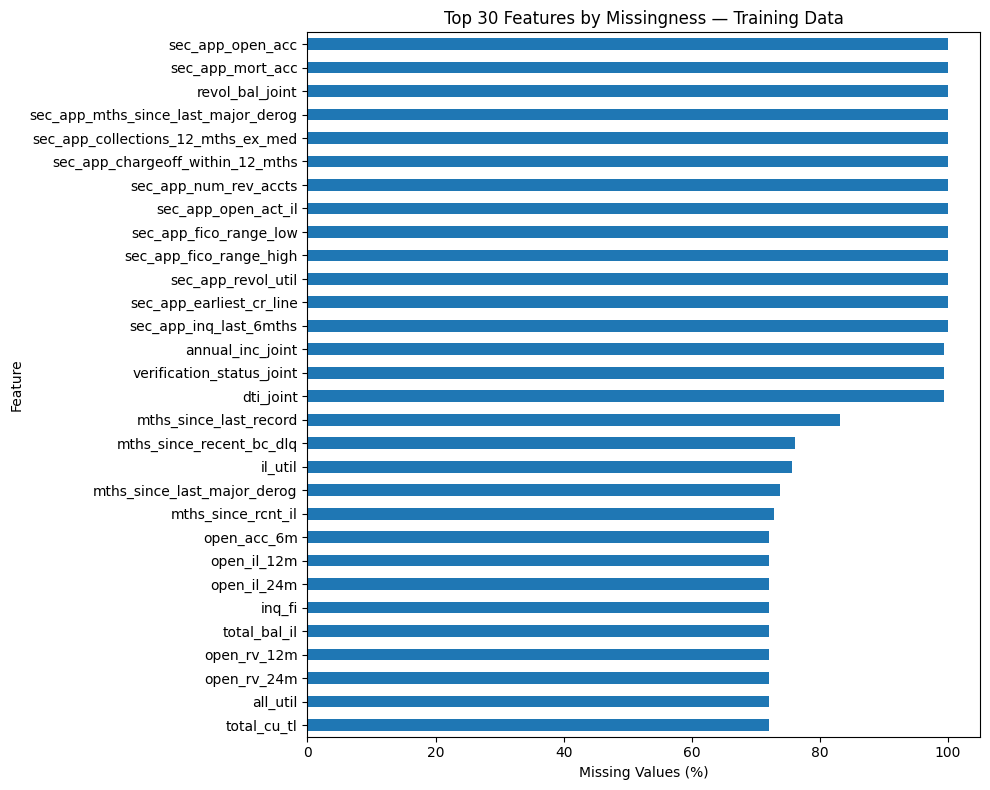

In [9]:
missing_pct = (
    train.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 8))

missing_pct.head(30).plot(kind="barh")

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Top 30 Features by Missingness — Training Data")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [10]:
missing_summary = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_pct": train.isna().mean() * 100,
    "unique_values": train.nunique(dropna=False)
})

missing_summary = (
    missing_summary[missing_summary["missing_pct"] > 0]
    .sort_values("missing_pct", ascending=False)
)

missing_summary.head(40)

,missing_count,missing_pct,unique_values
sec_app_mths_since_last_major_derog,99443,100.000000,1
sec_app_collections_12_mths_ex_med,99443,100.000000,1
sec_app_chargeoff_within_12_mths,99443,100.000000,1
sec_app_num_rev_accts,99443,100.000000,1
sec_app_open_act_il,99443,100.000000,1
sec_app_revol_util,99443,100.000000,1
sec_app_open_acc,99443,100.000000,1
revol_bal_joint,99443,100.000000,1
sec_app_mort_acc,99443,100.000000,1
sec_app_inq_last_6mths,99443,100.000000,1


In [12]:
# Compare default rate for missing vs non-missing values

features_to_check = [
    "mths_since_last_delinq",
    "mths_since_last_record",
    "emp_length",
    "revol_util",
    "mths_since_recent_inq",
    "il_util"
]

for col in features_to_check:
    temp = train.groupby(train[col].isna())["default_flag"].agg(
        loans="count",
        defaults="sum",
        default_rate="mean"
    )

    temp["default_rate"] *= 100

    print(f"\n{col}")
    print(temp)


mths_since_last_delinq
                        loans  defaults  default_rate
mths_since_last_delinq                               
False                   49512     10113     20.425351
True                    49931      9459     18.944143

mths_since_last_record
                        loans  defaults  default_rate
mths_since_last_record                               
False                   16819      3774     22.438908
True                    82624     15798     19.120352

emp_length
            loans  defaults  default_rate
emp_length                               
False       94070     18228     19.377060
True         5373      1344     25.013959

revol_util
            loans  defaults  default_rate
revol_util                               
False       99386     19560     19.680840
True           57        12     21.052632

mths_since_recent_inq
                       loans  defaults  default_rate
mths_since_recent_inq                               
False                  85617   

In [17]:
# ============================================================
# Missing vs Non-Missing Default Analysis
# ============================================================

rows = []

for col in train.columns:

    # Skip target itself
    if col == "default_flag":
        continue

    missing_mask = train[col].isna()
    non_missing_mask = ~missing_mask

    missing_count = missing_mask.sum()
    non_missing_count = non_missing_mask.sum()

    # Default rate among missing observations
    if missing_count > 0:
        missing_default_rate = (
            train.loc[missing_mask, "default_flag"].mean() * 100
        )
    else:
        missing_default_rate = np.nan

    # Default rate among non-missing observations
    if non_missing_count > 0:
        non_missing_default_rate = (
            train.loc[non_missing_mask, "default_flag"].mean() * 100
        )
    else:
        non_missing_default_rate = np.nan

    rows.append({
        "feature": col,
        "missing_count": missing_count,
        "non_missing_count": non_missing_count,
        "missing_pct": missing_count / len(train) * 100,
        "non_missing_pct": non_missing_count / len(train) * 100,
        "default_pct_missing": missing_default_rate,
        "default_pct_non_missing": non_missing_default_rate
    })


missing_default_analysis = pd.DataFrame(rows)

missing_default_analysis = missing_default_analysis.sort_values(
    "missing_pct",
    ascending=False
)
missing_default_analysis["default_rate_difference"] = (
    missing_default_analysis["default_pct_missing"]
    - missing_default_analysis["default_pct_non_missing"]
)

missing_default_analysis.sort_values(
    "default_rate_difference",
    ascending=False
)
pd.set_option("display.max_rows", None)

missing_default_analysis

,feature,missing_count,non_missing_count,missing_pct,non_missing_pct,default_pct_missing,default_pct_non_missing,default_rate_difference
37,annual_inc_joint,98888,555,99.441891,0.558109,19.663660,22.882883,-3.219223
38,dti_joint,98888,555,99.441891,0.558109,19.663660,22.882883,-3.219223
39,verification_status_joint,98888,555,99.441891,0.558109,19.663660,22.882883,-3.219223
26,mths_since_last_record,82624,16819,83.086793,16.913207,19.120352,22.438908,-3.318556
70,mths_since_recent_bc_dlq,75651,23792,76.074736,23.925264,19.346737,20.746469,-1.399732
49,il_util,75279,24164,75.700653,24.299347,18.499183,23.365337,-4.866154
34,mths_since_last_major_derog,73319,26124,73.729674,26.270326,18.955523,21.719492,-2.763969
47,mths_since_rcnt_il,72396,27047,72.801504,27.198496,18.404332,23.100529,-4.696197
52,max_bal_bc,71680,27763,72.081494,27.918506,18.342634,23.138710,-4.796076
51,open_rv_24m,71680,27763,72.081494,27.918506,18.342634,23.138710,-4.796076


In [15]:
# ============================================================
# Drop columns that are completely missing
# ============================================================

all_nan_cols = train.columns[train.isna().all()].tolist()

print("Columns that are 100% missing:")
print(all_nan_cols)

print(f"\nNumber of columns to drop: {len(all_nan_cols)}")

Columns that are 100% missing:
['revol_bal_joint', 'sec_app_fico_range_low', 'sec_app_fico_range_high', 'sec_app_earliest_cr_line', 'sec_app_inq_last_6mths', 'sec_app_mort_acc', 'sec_app_open_acc', 'sec_app_revol_util', 'sec_app_open_act_il', 'sec_app_num_rev_accts', 'sec_app_chargeoff_within_12_mths', 'sec_app_collections_12_mths_ex_med', 'sec_app_mths_since_last_major_derog']

Number of columns to drop: 13


In [16]:
train = train.drop(columns=all_nan_cols)
validation = validation.drop(columns=all_nan_cols)
oot_test = oot_test.drop(columns=all_nan_cols)

print("\nShapes after dropping 100% missing columns:")
print("Train      :", train.shape)
print("Validation :", validation.shape)
print("OOT Test   :", oot_test.shape)


Shapes after dropping 100% missing columns:
Train      : (99443, 97)
Validation : (14909, 97)
OOT Test   : (5019, 97)


Trying out WoE for emp_length

In [19]:
col = "emp_length"

train[[col, "default_flag"]].head(20)

,emp_length,default_flag
0,3 years,0
1,10+ years,0
2,1 year,0
3,10+ years,1
4,6 years,0
5,7 years,1
6,10+ years,0
7,3 years,0
8,10+ years,0
9,8 years,0


In [20]:
train[col].value_counts(dropna=False)

emp_length
10+ years    32611
2 years       8917
3 years       8035
< 1 year      7861
1 year        6561
5 years       6087
4 years       6026
NaN           5373
8 years       4745
6 years       4708
7 years       4612
9 years       3907
Name: count, dtype: int64

In [21]:
woe_table = (
    train.groupby(
        train[col].fillna("Missing"),
        dropna=False
    )["default_flag"]
    .agg(
        total="count",
        bad="sum"
    )
)

woe_table["good"] = woe_table["total"] - woe_table["bad"]

woe_table

,total,bad,good
emp_length,,,
1 year,6561,1301,5260
10+ years,32611,6118,26493
2 years,8917,1723,7194
3 years,8035,1551,6484
4 years,6026,1181,4845
5 years,6087,1166,4921
6 years,4708,896,3812
7 years,4612,929,3683
8 years,4745,926,3819


In [22]:
total_good = woe_table["good"].sum()
total_bad = woe_table["bad"].sum()

woe_table["dist_good"] = woe_table["good"] / total_good
woe_table["dist_bad"] = woe_table["bad"] / total_bad

woe_table

,total,bad,good,dist_good,dist_bad
emp_length,,,,,
1 year,6561,1301,5260,0.065856,0.066473
10+ years,32611,6118,26493,0.331697,0.312589
2 years,8917,1723,7194,0.090070,0.088034
3 years,8035,1551,6484,0.081181,0.079246
4 years,6026,1181,4845,0.060660,0.060341
5 years,6087,1166,4921,0.061612,0.059575
6 years,4708,896,3812,0.047727,0.045780
7 years,4612,929,3683,0.046112,0.047466
8 years,4745,926,3819,0.047815,0.047312


In [23]:
woe_table["woe"] = np.log(
    woe_table["dist_good"] / woe_table["dist_bad"]
)

woe_table

,total,bad,good,dist_good,dist_bad,woe
emp_length,,,,,,
1 year,6561,1301,5260,0.065856,0.066473,-0.009315
10+ years,32611,6118,26493,0.331697,0.312589,0.059332
2 years,8917,1723,7194,0.090070,0.088034,0.022868
3 years,8035,1551,6484,0.081181,0.079246,0.024125
4 years,6026,1181,4845,0.060660,0.060341,0.005273
5 years,6087,1166,4921,0.061612,0.059575,0.033620
6 years,4708,896,3812,0.047727,0.045780,0.041656
7 years,4612,929,3683,0.046112,0.047466,-0.028939
8 years,4745,926,3819,0.047815,0.047312,0.010557


In [24]:
woe_table["iv"] = (
    (woe_table["dist_good"] - woe_table["dist_bad"])
    * woe_table["woe"]
)

woe_table

,total,bad,good,dist_good,dist_bad,woe,iv
emp_length,,,,,,,
1 year,6561,1301,5260,0.065856,0.066473,-0.009315,0.000006
10+ years,32611,6118,26493,0.331697,0.312589,0.059332,0.001134
2 years,8917,1723,7194,0.090070,0.088034,0.022868,0.000047
3 years,8035,1551,6484,0.081181,0.079246,0.024125,0.000047
4 years,6026,1181,4845,0.060660,0.060341,0.005273,0.000002
5 years,6087,1166,4921,0.061612,0.059575,0.033620,0.000068
6 years,4708,896,3812,0.047727,0.045780,0.041656,0.000081
7 years,4612,929,3683,0.046112,0.047466,-0.028939,0.000039
8 years,4745,926,3819,0.047815,0.047312,0.010557,0.000005


In [25]:
iv = woe_table["iv"].sum()

print(f"IV for {col}: {iv:.6f}")

IV for emp_length: 0.007564
